In [11]:
#Extract Data
import glob
import os
import pandas as pd
import numpy as np

# ── Locate all CSV files ────────────────────────────────────────────────────
csv_dir = "/scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e5*/csv_output/"
csv_files = sorted(glob.glob(os.path.join(csv_dir, "*.csv")))

print(f"Found {len(csv_files)} CSV files in {csv_dir}")
for f in csv_files:
    print(f"  {f}")

if not csv_files:
    raise SystemExit(f"No CSV files found in {csv_dir}")

# ── Load and concatenate all CSVs into one DataFrame ────────────────────────
dfs = []
for f in csv_files:
    try:
        df_i = pd.read_csv(f)
        df_i["__source_file"] = os.path.basename(f)  # keep provenance, optional
        dfs.append(df_i)
    except Exception as e:
        print(f"WARNING: failed to read {f}: {e}")

if not dfs:
    raise SystemExit("No CSV files could be read successfully.")

df = pd.concat(dfs, ignore_index=True)
print(f"Combined DataFrame shape: {df.shape}")

# ── Helper functions ─────────────────────────────────────────────────────────
def slant_depth(zem, obs_height, zenith_rad):
    theta = np.pi - zenith_rad
    arg = (obs_height / zem) * np.sin(theta)
    arg = np.clip(arg, -1.0, 1.0)
    beta = np.where(np.isfinite(arg), np.arcsin(arg), 0.0)
    beta = np.clip(beta, 0.0, np.pi / 2)
    alpha = np.pi - theta - beta
    s = zem * np.sin(alpha) / np.sin(theta)
    return np.clip(s, 0, np.inf)

def incidence_angle(Zenith_deg, Azimuth_deg):
    cos_Zenith = np.cos(np.radians(Zenith_deg))
    cos_Azimuth = np.cos(np.radians(Azimuth_deg - 180))
    cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
    Incidence = np.degrees(np.arccos(cos_Incidence))
    return Incidence

# ── Derived columns (same as your single-file version, now on combined df) ──
X = np.array(df["tel_x"])            # m
Z = np.array(df["tel_z"])            # m
R = np.sqrt(X**2 + Z**2)             # m
H = np.array(df["height"])           # m
Zenith = np.array(df["zen"])         # deg
Azimuth = np.array(df["az"])         # deg
try:
    Inj_Zenith = np.array(df["injection_zenith_deg"])
    Inj_Azimuth = np.array(df["injection_azimuth_deg"])
    Inj_x       = np.array(df["injection_x"])
    Inj_y       = np.array(df["injection_y"])
    Inj_z       = np.array(df["injection_z_minus_R_m"])
    Inj_r       = np.sqrt(Inj_x**2 + Inj_y**2 +Inj_z**2)
    x_mag  = np.array(df["x_mag"])
    y_mag  = np.array(df["y_mag"])
    z_mag  = np.array(df["z_mag"])
    Slant  = np.sqrt((x_mag - Inj_x)**2 + (y_mag - Inj_y)**2 +(z_mag - Inj_z)**2)/1000  # km
except:
    Slant = slant_depth(H + 6371e3, 2944 + 6371e3, np.radians(Zenith)) / 1000  # km
    pass
Max_PE = np.array(df["max_pe"])      # photo-electron
Time_at_Max_PE = np.array(df["time_at_max_pe_ns"])  # ns
Avg_PE = np.array(df["avg_pe"])
Total_PE = np.array(df["total_pe"])
Energy_GeV = np.array(df["energy_string"])          # GeV

Ground_Energy = np.array(df["max_muon_energy_GeV"]) # GeV


cos_Zenith = np.cos(np.radians(Zenith))
cos_Azimuth = np.cos(np.radians(Azimuth - 180))
cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
Incidence = incidence_angle(Zenith, Azimuth)  # deg
Inj_Incidence = incidence_angle(Inj_Zenith, Inj_Azimuth) 
x_corr = np.array(df["correction_x_m"])  # m
y_corr = np.array(df["correction_y_m"])  # m


r99_m = np.array(df["r99_m"])
r68_m = np.array(df["r68_m"])
seed = np.array(df["seed"])

file_size = np.array(df["file_size_MB"])  # MB
photon_count = np.array(df["cph_photon_count"])
max_photon_10ns = np.array(df["cph_max_photons_10ns"])
E_list = np.sort(np.array(list(set(Energy_GeV))))
deleted_low_pe = np.array(df["deleted_low_pe"])
runtime_hours = np.array(df["runtime_seconds"]) / 3600

#Weighted Photon Count:
try:
    N_PC_BINS = 1000
    FLAT_IN = "log"                        # "log" or "lin"
    W_CAP = 20
    pc_range = np.log10([min(photon_count[photon_count>0]), max(photon_count)])
    w_edges = np.logspace(*pc_range, N_PC_BINS + 1)
    h, _ = np.histogram(photon_count, bins=w_edges)
    idx = np.clip(np.digitize(photon_count, w_edges) - 1, 0, N_PC_BINS - 1)
    target = np.diff(w_edges) if FLAT_IN == "lin" else np.ones(N_PC_BINS)
    weights_pc = target[idx] / h[idx]
    weights_pc *= len(weights_pc) / weights_pc.sum()
except Exception as e:
    print(f"WARNING: failed to compute weights_pc: {e}")
    weights_pc = np.ones_like(photon_count)

total_particles    = np.array(df["total_particles"])
muon_component     = np.array(df["muon_component"])
electron_component = np.array(df["electron_component"])
hadronic_component = np.array(df["hadronic_component"])
gamma_component    = np.array(df["gamma_component"])
other_component    = np.array(df["other_component"])

# ── Summary stats ─────────────────────────────────────────────────────────
print(f"Total events: {len(df)}")
print(f"Total events with Max_PE >= 20: {np.sum(Max_PE >= 20)}")
print(f"Max_PE  -> max={np.nanmax(Max_PE):.4f}, min={np.nanmin(Max_PE):.4f}, median={np.nanmedian(Max_PE):.4f}")
print(f"Zenith  -> max={np.nanmax(Zenith):.2f}, min={np.nanmin(Zenith):.2f}, median={np.nanmedian(Zenith):.2f}")
print(f"Azimuth -> max={np.nanmax(Azimuth):.2f}, min={np.nanmin(Azimuth):.2f}, median={np.nanmedian(Azimuth):.2f}")
print(f"Production Height -> max={np.nanmax(H):.2f}, min={np.nanmin(H):.2f}, median={np.nanmedian(H):.2f}")
print(f"Unique energies found: {E_list}")

Found 3 CSV files in /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e5*/csv_output/
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e5_R1/csv_output/adaptive_pid13_E1e5_R1_y0.0_zen90.0_az269.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e5_R1/csv_output/adaptive_pid13_E1e5_R1_y0.0_zen90.0_az270.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e5_R1/csv_output/adaptive_pid13_E1e5_R1_y0.0_zen90.0_az271.0.csv
Combined DataFrame shape: (88584, 61)
Total events: 88584
Total events with Max_PE >= 20: 79
Max_PE  -> max=149.2116, min=0.0000, median=0.0000
Zenith  -> max=99.95, min=89.95, median=90.00
Azimuth -> max=285.63, min=268.97, median=270.00
Production Height -> max=80000.00, min=4000.00, median=4000.00
Unique energies found: [100000.]


In [12]:
set(H)

{np.float64(4000.0),
 np.float64(6000.0),
 np.float64(8000.0),
 np.float64(11000.0),
 np.float64(15000.0),
 np.float64(21000.0),
 np.float64(29000.0),
 np.float64(41000.0),
 np.float64(57000.0),
 np.float64(80000.0)}

In [7]:
mask = (Max_PE>= 149)&(np.round(Zenith) == 90)&(np.round(Azimuth)==270)
seed[mask], Azimuth[mask], H[mask]

(array([80, 81, 10, 27, 69, 82, 32,  4, 87,  3, 32,  7, 12, 20, 21, 74, 83,
        91, 74, 81, 20, 84, 90]),
 array([270.0016, 270.003 , 270.0001, 270.0002, 270.0001, 270.0002,
        270.0002, 270.0003, 270.0003, 270.0004, 270.0003, 270.0002,
        270.0003, 270.0004, 270.0005, 270.0004, 270.0006, 270.0005,
        270.0007, 270.0007, 270.0009, 270.0008, 270.0009]),
 array([ 8000., 15000.,  6000.,  6000.,  6000.,  6000.,  8000., 15000.,
        15000., 21000., 21000., 29000., 29000., 29000., 29000., 29000.,
        29000., 29000., 57000., 57000., 80000., 80000., 80000.]))

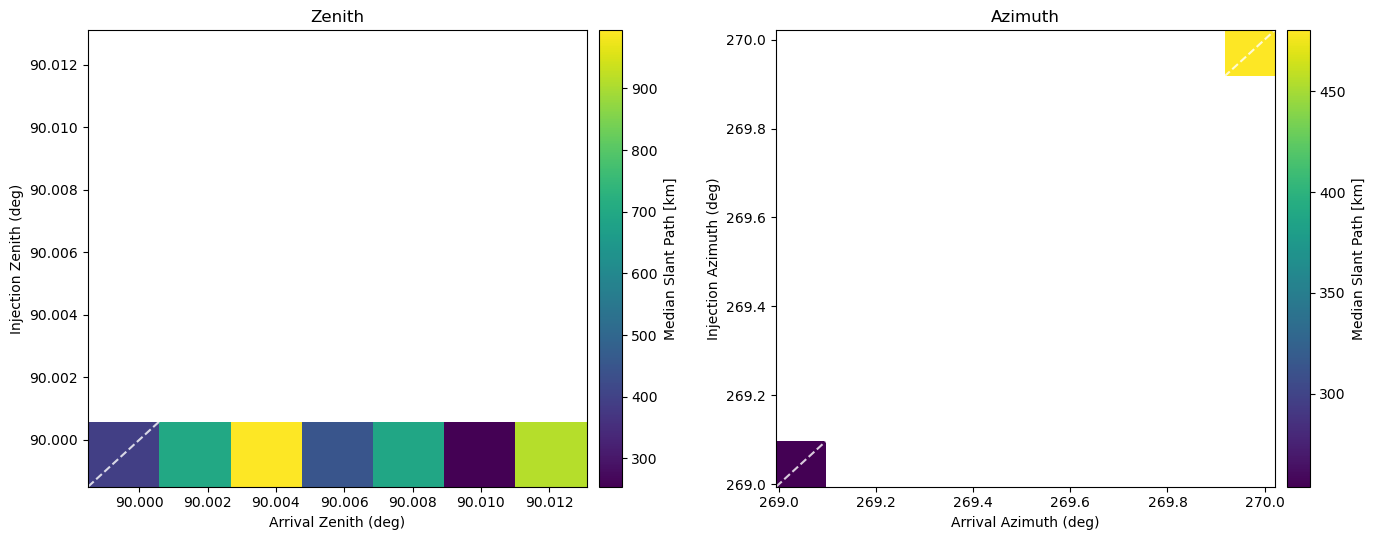

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic_2d

# ── Settings ──────────────────────────────────────────────────────────────
N_BINS      = 7           # bins per axis
N_BINS_AZ   = 10
MIN_COUNT   = 0            # mask bins with fewer events than this
STAT        = 'median'     # 'median' or 'mean'
SLANT_LABEL = 'Median Slant Path [km]'   # <-- adjust unit if needed
CMAP        = 'viridis'    # perceptually uniform, colour-blind friendly

def slant_map(ax, x, y, s, x_edges, y_edges, xlabel, ylabel, title):
    stat, xe, ye, _ = binned_statistic_2d(x, y, s, statistic=STAT,
                                          bins=[x_edges, y_edges])
    cnt, _, _, _    = binned_statistic_2d(x, y, None, statistic='count',
                                          bins=[x_edges, y_edges])
    stat = np.ma.masked_where((cnt < MIN_COUNT) | ~np.isfinite(stat), stat)

    mesh = ax.pcolormesh(xe, ye, stat.T, shading='flat', cmap=CMAP)
    lo, hi = max(xe[0], ye[0]), min(xe[-1], ye[-1])
    ax.plot([lo, hi], [lo, hi], 'w--', lw=1.5, alpha=0.8)   # y = x reference
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    cbar = plt.colorbar(mesh, ax=ax, pad=0.02)
    cbar.set_label(SLANT_LABEL)
    return stat, cnt

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ── Zenith ────────────────────────────────────────────────────────────────
mz = (np.isfinite(Zenith) & np.isfinite(Inj_Zenith) & np.isfinite(Slant)
      & (photon_count > 0))
z_edges = np.linspace(min(Zenith[mz].min(), Inj_Zenith[mz].min()),
                      max(Zenith[mz].max(), Inj_Zenith[mz].max()), N_BINS + 1)
slant_map(axes[0], Zenith[mz], Inj_Zenith[mz], Slant[mz], z_edges, z_edges,
          "Arrival Zenith (deg)", "Injection Zenith (deg)", "Zenith")

# ── Azimuth ───────────────────────────────────────────────────────────────
ma = (np.isfinite(Azimuth) & np.isfinite(Inj_Azimuth) & np.isfinite(Slant)
      & (photon_count > 0))
a_edges = np.linspace(min(Azimuth[ma].min(), Inj_Azimuth[ma].min()),
                      max(Azimuth[ma].max(), Inj_Azimuth[ma].max()), N_BINS_AZ + 1)
slant_map(axes[1], Azimuth[ma], Inj_Azimuth[ma], Slant[ma], a_edges, a_edges,
          "Arrival Azimuth (deg)", "Injection Azimuth (deg)", "Azimuth")

fig.tight_layout()
plt.show()

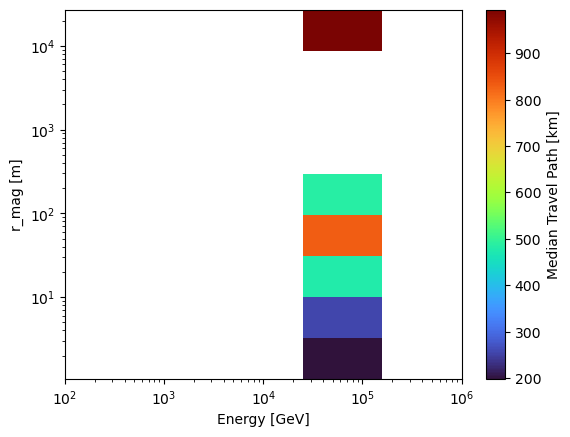

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import binned_statistic_2d
# Convert to km once, and build a clean mask
r_mag = np.sqrt(x_mag**2 + z_mag**2 + y_mag**2)    # m

valid = (
    (photon_count >= 0)
    & np.isfinite(r_mag) & (r_mag > 0)
    & np.isfinite(Energy_GeV) & (Energy_GeV > 0)
    & np.isfinite(Slant)
)

E = Energy_GeV[valid]
R = r_mag[valid]
S = Slant[valid]

E_bins = np.logspace(2, 6, 6)    # 5 bins from 10 GeV to 1e6 GeV (note: 6 edges)
R_bins = np.logspace(np.log10(R.min()), np.log10(R.max()), 10)

stat, xedges, yedges, binnumber = binned_statistic_2d(
    E, R, S, statistic='median', bins=[E_bins, R_bins]
)

plt.figure()
mesh = plt.pcolormesh(xedges, yedges, stat.T, shading='auto',
                      cmap='turbo')#, norm=LogNorm())
plt.xscale('log')
plt.yscale('log')
cbar = plt.colorbar(mesh)
cbar.set_label('Median Travel Path [km]')
plt.xlabel('Energy [GeV]')
plt.ylabel('r_mag [m]')
plt.show()

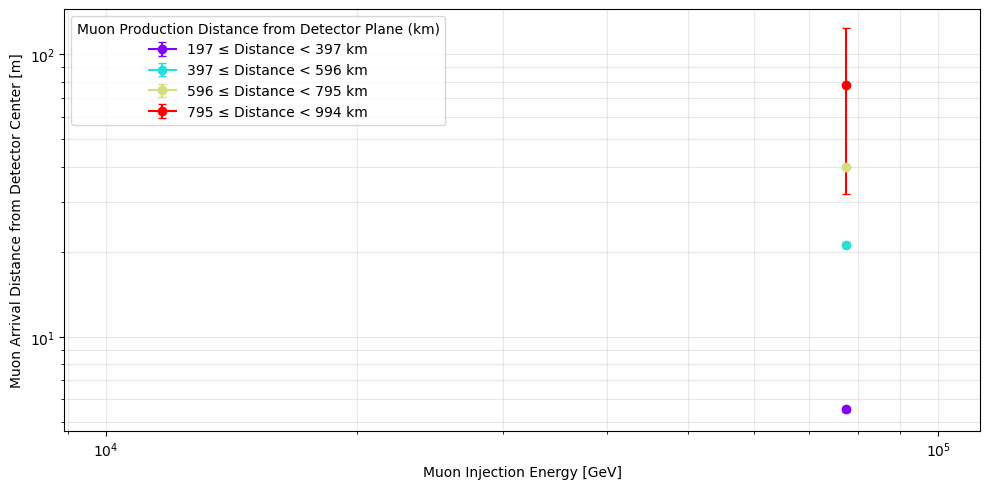

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Convert to km once, and build a clean mask
r_mag = np.sqrt(x_mag**2 + z_mag**2 + y_mag**2)   # m
r_corr = np.sqrt(x_corr**2+y_corr**2)#
valid = (
    (photon_count >= 0) #& (H <= 20000)
    & np.isfinite(r_mag) & (r_mag > 0)
    & np.isfinite(Energy_GeV) & (Energy_GeV > 0)
    & np.isfinite(Slant)
)

E = Energy_GeV[valid]
R = r_mag[valid]
S = Slant[valid]

# ---- user settings ---------------------------------------------
SLANT_BINS = np.linspace(min((S)), (np.max(S)), 5)   # Slant bin edges (same units as Slant)
E_bins     = np.logspace(2, 6, 10)        # energy bins (8 bins, 1e2–1e5 GeV)
ERR_MODE   = "sem"                       # "pct" = 16–84 % spread, "sem" = std. error of mean
MIN_COUNT  =  2                         # skip energy bins with fewer muons than this
# ----------------------------------------------------------------

E_centers = np.sqrt(E_bins[:-1] * E_bins[1:])   # geometric bin centres
colors = plt.cm.rainbow(np.linspace(0, 1, len(SLANT_BINS) - 1))

plt.figure(figsize=(10, 5))
for i, (s_lo, s_hi) in enumerate(zip(SLANT_BINS[:-1], SLANT_BINS[1:])):
    in_s = (S >= s_lo) & (S < s_hi)
    if not np.any(in_s):
        continue
    Es, Rs = E[in_s], R[in_s]
    idx = np.digitize(Es, E_bins) - 1

    x, y, lo, hi = [], [], [], []
    for j in range(len(E_bins) - 1):
        r = Rs[idx == j]
        if r.size < MIN_COUNT:
            continue
        med = np.median(r)
        if ERR_MODE == "sem":
            e = np.std(r, ddof=1) / np.sqrt(r.size)
            el, eh = e, e
        else:
            p16, p84 = np.percentile(r, [16, 84])
            el, eh = med - p16, p84 - med
        x.append(E_centers[j]); y.append(med); lo.append(el); hi.append(eh)

    if x:
        y, lo = np.array(y), np.array(lo)
        lo = np.minimum(lo, y * 0.999)   # keep lower bar > 0 on log axis
        plt.errorbar(x, y, yerr=[lo, hi], fmt='o-', capsize=3,
                     color=colors[i], label=f'{np.round(s_lo):g} ≤ Distance < {np.round(s_hi):g} km')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Muon Injection Energy [GeV]')
plt.ylabel('Muon Arrival Distance from Detector Center [m]')
plt.legend(title='Muon Production Distance from Detector Plane (km)')
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
#Define Backtrack muon
import numpy as np
import shlex

# ===============================================================
# Constants
# ===============================================================
C          = 299792458.0
E_CHARGE   = 1.602176634e-19
MEV_TO_J   = 1.602176634e-13
M_MU_MEV   = 105.6583755
R_EARTH    = 6371e3
TAU_MU_S   = 2.1969811e-6


# ===============================================================
# Exact vectorized constant-field helix
# Unique name: unaffected by an older function named _helix.
# ===============================================================
def _muon_helix_vectorized(x0, u0, pc, charge, B, s):
    """
    x0, u0: (..., 3)
    pc: momentum*c [MeV]
    charge: charge in units of elementary charge
    B: shared magnetic field, shape (3,), [T]
    s: path length [m]
    """
    x0 = np.asarray(x0, dtype=float)
    u0 = np.asarray(u0, dtype=float)
    B = np.asarray(B, dtype=float)

    pc, charge, s = np.broadcast_arrays(
        np.asarray(pc, dtype=float),
        np.asarray(charge, dtype=float),
        np.asarray(s, dtype=float),
    )

    shape = np.broadcast_shapes(
        x0.shape[:-1], u0.shape[:-1], pc.shape
    )

    x0 = np.broadcast_to(x0, shape + (3,))
    u0 = np.broadcast_to(u0, shape + (3,))
    pc = np.broadcast_to(pc, shape)
    charge = np.broadcast_to(charge, shape)
    s = np.broadcast_to(s, shape)

    Bmag = np.linalg.norm(B)

    if Bmag == 0.0:
        return x0 + s[..., None] * u0, u0.copy()

    bhat = B / Bmag

    u_parallel = np.sum(
        u0 * bhat, axis=-1, keepdims=True
    ) * bhat

    u_perp = u0 - u_parallel
    w = np.cross(bhat, u_perp)

    angle = (
        -charge * E_CHARGE * Bmag * C / MEV_TO_J
    ) * s / pc

    # Stable at angle = 0.
    sinc = np.sinc(angle / np.pi)
    cosc = (
        0.5 * angle
        * np.sinc(angle / (2.0 * np.pi))**2
    )

    x = x0 + s[..., None] * (
        u_parallel
        + sinc[..., None] * u_perp
        + cosc[..., None] * w
    )

    u = (
        u_parallel
        + np.cos(angle)[..., None] * u_perp
        + np.sin(angle)[..., None] * w
    )

    u /= np.linalg.norm(u, axis=-1, keepdims=True)

    return x, u


# ===============================================================
# Shared numerical implementation for BOTH scalar and grid calls
# ===============================================================
def _muon_backtrack_core(
    E_tot_GeV,
    charge_sign,
    zenith_deg,
    azimuth_deg,
    h_prod_m,
    H_obs_m=3000.0,
    B_vec=(28.6e-6, 0.0, -46.4e-6),
    R_earth=R_EARTH,
    scan_step_m=500.0,
    max_path_m=2_000_000.0,
    path_tol_m=1e-6,
    max_scan_rotation_rad=0.02,
):
    """
    Constant-energy, uniform-field geometric backtracking.

    Angles describe FORWARD travel:
        u = (sin(zen)*cos(az), sin(zen)*sin(az), -cos(zen))

    Production altitude is spherical:
        norm(x_prod) = R_earth + h_prod_m

    Backtracking reverses velocity AND charge, keeping B unchanged.

    Scalar inputs return scalars and shape-(3,) vectors.
    Array inputs follow NumPy broadcasting.

    Search limitations:
      - First sign-changing crossing detected by the scan.
      - Tangencies / multiple crossings within one interval can be missed.
      - No ground rejection or material interactions.
      - Equal detector/production heights return s = 0.
    """
    arrays = np.broadcast_arrays(
        *[
            np.asarray(v, dtype=float)
            for v in (
                E_tot_GeV,
                charge_sign,
                zenith_deg,
                azimuth_deg,
                h_prod_m,
                H_obs_m,
            )
        ]
    )

    shape = arrays[0].shape
    E, q, zen, azi, hp, ho = [
        a.ravel() for a in arrays
    ]

    B = np.asarray(B_vec, dtype=float)

    if B.shape != (3,) or not np.all(np.isfinite(B)):
        raise ValueError("B_vec must contain three finite numbers.")

    if E.size == 0:
        raise ValueError("Muon inputs cannot be empty.")

    if not all(np.all(np.isfinite(a)) for a in arrays):
        raise ValueError("All muon inputs must be finite.")

    if np.any(E <= M_MU_MEV / 1000.0):
        raise ValueError("Total energy must exceed muon rest energy.")

    if np.any((q != -1) & (q != 1)):
        raise ValueError("charge_sign must be -1 or +1.")

    if np.any((zen < 0) | (zen > 180)):
        raise ValueError("zenith_deg must be in [0, 180].")

    if np.any(hp < 0) or np.any(ho < 0):
        raise ValueError("Production/detector heights must be >= 0.")

    controls = (
        R_earth,
        scan_step_m,
        max_path_m,
        path_tol_m,
        max_scan_rotation_rad,
    )
    if any(not np.isfinite(v) or v <= 0 for v in controls):
        raise ValueError("Earth radius and search controls must be positive.")

    E_MeV = E * 1000.0
    pc = np.sqrt(
        (E_MeV - M_MU_MEV) * (E_MeV + M_MU_MEV)
    )

    th = np.radians(zen)
    ph = np.radians(azi)

    u_tel = np.stack(
        [
            np.sin(th) * np.cos(ph),
            np.sin(th) * np.sin(ph),
            -np.cos(th),
        ],
        axis=-1,
    )

    x_tel = np.zeros((E.size, 3))
    x_tel[:, 2] = R_earth + ho

    target_r = R_earth + hp

    def backward(s, indices):
        return _muon_helix_vectorized(
            x_tel[indices],
            -u_tel[indices],
            pc[indices],
            -q[indices],
            B,
            s,
        )

    def residual(s, indices):
        x, _ = backward(s, indices)
        return np.linalg.norm(x, axis=-1) - target_r[indices]

    kb = E_CHARGE * np.linalg.norm(B) * C / MEV_TO_J

    if kb == 0.0:
        step = np.full(E.size, scan_step_m)
    else:
        step = np.minimum(
            scan_step_m,
            max_scan_rotation_rad * pc / kb,
        )

    lo = np.zeros(E.size)
    hi = np.zeros(E.size)
    flo = ho - hp

    found = (ho == hp)
    active = ~found

    # -----------------------------------------------------------
    # Bracket each trajectory independently.
    # No Python loop over muons.
    # -----------------------------------------------------------
    while np.any(active):
        idx = np.flatnonzero(active)

        trial = np.minimum(
            lo[idx] + step[idx], max_path_m
        )

        if np.any(trial <= lo[idx]):
            raise RuntimeError(
                "Scan cannot advance at floating-point precision."
            )

        ft = residual(trial, idx)

        crossed = (
            (ft == 0.0)
            | (np.signbit(ft) != np.signbit(flo[idx]))
        )

        hit = idx[crossed]
        hi[hit] = trial[crossed]
        found[hit] = True
        active[hit] = False

        miss = idx[~crossed]
        lo[miss] = trial[~crossed]
        flo[miss] = ft[~crossed]
        active[miss] = trial[~crossed] < max_path_m

    # -----------------------------------------------------------
    # Bisection, including exact-root and roundoff handling.
    # -----------------------------------------------------------
    active = found & ((hi - lo) > path_tol_m)

    while np.any(active):
        idx = np.flatnonzero(active)
        mid = lo[idx] + 0.5 * (hi[idx] - lo[idx])

        stalled = (mid == lo[idx]) | (mid == hi[idx])
        if np.any(stalled):
            active[idx[stalled]] = False

        idx = idx[~stalled]
        mid = mid[~stalled]

        if idx.size == 0:
            continue

        fm = residual(mid, idx)
        exact = (fm == 0.0)

        root = idx[exact]
        lo[root] = mid[exact]
        hi[root] = mid[exact]
        flo[root] = 0.0

        remaining = idx[~exact]
        middle = mid[~exact]
        fmiddle = fm[~exact]

        left = (
            np.signbit(fmiddle)
            != np.signbit(flo[remaining])
        )

        hi[remaining[left]] = middle[left]
        lo[remaining[~left]] = middle[~left]
        flo[remaining[~left]] = fmiddle[~left]

        active[idx] = (
            (hi[idx] - lo[idx]) > path_tol_m
        )

    s = np.where(
        found, lo + 0.5 * (hi - lo), np.nan
    )

    x_prod = np.full((E.size, 3), np.nan)
    u_inj = np.full((E.size, 3), np.nan)

    position_error = np.full(E.size, np.nan)
    direction_error = np.full(E.size, np.nan)
    altitude_error = np.full(E.size, np.nan)

    idx = np.flatnonzero(found)

    if idx.size:
        xp, ub = backward(s[idx], idx)
        x_prod[idx] = xp
        u_inj[idx] = -ub

        xr, ur = _muon_helix_vectorized(
            x_prod[idx],
            u_inj[idx],
            pc[idx],
            q[idx],
            B,
            s[idx],
        )

        position_error[idx] = np.linalg.norm(
            xr - x_tel[idx], axis=-1
        )
        direction_error[idx] = np.linalg.norm(
            ur - u_tel[idx], axis=-1
        )
        altitude_error[idx] = (
            np.linalg.norm(xp, axis=-1) - target_r[idx]
        )

    theta = np.degrees(
        np.arccos(np.clip(-u_inj[:, 2], -1.0, 1.0))
    )

    phi = np.degrees(
        np.arctan2(u_inj[:, 1], u_inj[:, 0])
    ) % 360.0

    beta = pc / E_MeV
    gamma = E_MeV / M_MU_MEV

    flight_time = s / (beta * C)
    proper_time = s * M_MU_MEV / (pc * C)
    exponent = proper_time / TAU_MU_S

    result = dict(
        success=found,
        pdg=(-13 * q).astype(int),
        charge_sign=q,

        detector_zenith_deg=zen,
        detector_azimuth_deg=azi % 360.0,
        production_altitude_m=hp,

        injection_zenith_deg=theta,
        injection_azimuth_deg=phi,
        injection_x_m=x_prod[:, 0],
        injection_y_m=x_prod[:, 1],

        # Preserve YOUR existing command-height convention.
        injection_height_m=hp,

        # Distinct quantity: Cartesian z minus Earth radius.
        injection_z_minus_R_m=x_prod[:, 2] - R_earth,

        injection_total_energy_GeV=E,
        observation_level_m=ho,

        position_earth_m=x_prod,
        direction_unit=u_inj,
        path_length_m=s,

        beta=beta,
        gamma=gamma,
        flight_time_s=flight_time,
        proper_time_s=proper_time,
        survival_probability=np.exp(-exponent),
        decay_probability=-np.expm1(-exponent),

        forward_position_error_m=position_error,
        forward_direction_error=direction_error,
        production_altitude_error_m=altitude_error,
    )

    vector_keys = {"position_earth_m", "direction_unit"}

    for key, value in result.items():
        trailing = (3,) if key in vector_keys else ()
        value = value.reshape(shape + trailing)
        result[key] = (
            value.item() if value.ndim == 0 else value
        )

    return result


# ===============================================================
# Public scalar/broadcast interface
# ===============================================================
def back_track_muon(
    E_tot_GeV,
    charge_sign,
    zenith_deg,
    azimuth_deg,
    h_prod_m,
    **kwargs,
):
    return _muon_backtrack_core(
        E_tot_GeV,
        charge_sign,
        zenith_deg,
        azimuth_deg,
        h_prod_m,
        **kwargs,
    )


# Explicit alternative name.
back_track_muon_vectorized = back_track_muon


# ===============================================================
# Cartesian-product grid interface
# Calls the private core, NOT the public scalar function.
# ===============================================================
def back_track_muon_grid(
    E_tot_GeV,
    charge_sign,
    zenith_deg,
    azimuth_deg,
    h_prod_m,
    **kwargs,
):
    """
    Scalar-field output shape:
        (energy, charge, zenith, azimuth, production_height)

    Vector fields have an additional final dimension of 3.
    """
    inputs = [
        np.asarray(v, dtype=float)
        for v in (
            E_tot_GeV,
            charge_sign,
            zenith_deg,
            azimuth_deg,
            h_prod_m,
        )
    ]

    if any(a.ndim > 1 for a in inputs):
        raise ValueError("Grid inputs must be scalars or 1-D arrays.")

    if any(a.size == 0 for a in inputs):
        raise ValueError("Grid inputs cannot be empty.")

    E, Q, Z, A, H = np.meshgrid(
        *(np.atleast_1d(a) for a in inputs),
        indexing="ij",
        sparse=True,
    )

    return _muon_backtrack_core(
        E, Q, Z, A, H, **kwargs
    )


# ===============================================================
# Extract one result, preserving vector fields
# ===============================================================
def select_muon(res, idx):
    """
    Example:
        one = select_muon(res, (0, 0, 3, 5, 0))
    """
    shape = np.asarray(res["success"]).shape

    if not isinstance(idx, tuple):
        idx = (idx,)

    if len(idx) != len(shape):
        raise ValueError(
            f"Expected {len(shape)} indices for shape {shape}."
        )

    if not all(isinstance(i, (int, np.integer)) for i in idx):
        raise ValueError("Use integer indices, not slices.")

    selected = {}

    for key, value in res.items():
        element = np.asarray(value)[idx]
        selected[key] = (
            element.item()
            if element.ndim == 0
            else element.copy()
        )

    if not selected["success"]:
        raise ValueError(f"No successful crossing at index {idx}.")

    return selected


# ===============================================================
# Command generation
# ===============================================================
def c8_commands(
    res,
    out="backtrack_muon",
    extra="",
    executable="corsika-install/bin/muon_cherenkov_3d",
    print_commands=True,
    height_mode="spherical",
):
    """
    Return a flat list of commands.

    height_mode:
        "spherical": use h_prod_m (your existing convention).
        "z_minus_R": use computed Cartesian z - R.

    Choose the mode matching your executable's interpretation of
    --injection-height; these quantities are not interchangeable.

    --observation-level is added unless already present in extra.
    """
    ok = np.asarray(res["success"]).ravel()

    if not np.all(ok):
        raise ValueError(
            "Some trajectories have no crossing. "
            "Select successful elements before generating commands."
        )

    if height_mode not in ("spherical", "z_minus_R"):
        raise ValueError(
            "height_mode must be 'spherical' or 'z_minus_R'."
        )

    height_key = (
        "injection_height_m"
        if height_mode == "spherical"
        else "injection_z_minus_R_m"
    )

    def flat(key):
        return np.asarray(res[key]).ravel()

    pdg = flat("pdg")
    energy = flat("injection_total_energy_GeV")
    height = flat(height_key)
    x = flat("injection_x_m")
    y = flat("injection_y_m")
    zen = flat("injection_zenith_deg")
    azi = flat("injection_azimuth_deg")
    obs = flat("observation_level_m")

    extra = extra.strip()
    tokens = shlex.split(extra)

    has_observation = any(
        token == "--observation-level"
        or token.startswith("--observation-level=")
        for token in tokens
    )

    commands = []

    for i in range(ok.size):
        output = out if ok.size == 1 else f"{out}_{i}"

        cmd = (
            f"{shlex.quote(executable)} "
            f"--pdg {int(pdg[i])} "
            f"-E {energy[i]:.15g} "
            f"--injection-height {height[i]:.15g} "
            f"--injection-x {x[i]:.15g} "
            f"--injection-y {y[i]:.15g} "
            f"--injection-zenith {zen[i]:.15g} "
            f"--injection-azimuth {azi[i]:.15g} "
        )

        if not has_observation:
            cmd += f"--observation-level {obs[i]:.15g} "

        cmd += f"-f {shlex.quote(output)}"

        if extra:
            cmd += " " + extra

        commands.append(cmd)

    if print_commands:
        print("\n".join(commands))

    return commands


def c8_command(
    res,
    pdg=None,
    out="backtrack_muon",
    extra="",
    **kwargs,
):
    """
    Generate one command. PDG is inferred from the result.
    Optional pdg is checked for consistency.
    """
    if np.asarray(res["success"]).size != 1:
        raise ValueError(
            "Select one muon first using select_muon()."
        )

    actual_pdg = int(np.asarray(res["pdg"]).item())

    if pdg is not None and pdg != actual_pdg:
        raise ValueError(
            f"Requested PDG {pdg}, but result has PDG {actual_pdg}."
        )

    return c8_commands(
        res,
        out=out,
        extra=extra,
        **kwargs,
    )[0]

In [2]:
#Generate input for CORSIKA8
E_TOT_GEV = [100]#p.logspace(1, 3, 10)#np.array([10, 20, 30, 50, 70, 100, 1000])
ZENITH_DEG = np.arange(85.0, 92.0, 0.1)
AZIMUTH_DEG = np.arange(265.0, 276.0, 0.1)

H_DET_KM = 3.0
H_TOP_KM = 112.8
H_STEP_KM = 2.0
N_H = 20

H_TARGET_M = np.geomspace(
    H_DET_KM + H_STEP_KM,
    H_TOP_KM,
    N_H,
) * 1e3

res = back_track_muon_grid(
    E_tot_GeV=E_TOT_GEV,
    charge_sign=[1,-1],           # or [-1, +1] for both charges
    zenith_deg=ZENITH_DEG,
    azimuth_deg=AZIMUTH_DEG,
    h_prod_m=H_TARGET_M,
    H_obs_m=H_DET_KM * 1e3,
)

print("Grid shape:", res["success"].shape)
# (3, 1, 5, 11, 20)

print("Total combinations:", res["success"].size)
print("Successful crossings:", np.count_nonzero(res["success"]))


Grid shape: (1, 2, 70, 110, 20)
Total combinations: 308000
Successful crossings: 306029


In [40]:
# Axes: (energy, charge, detector zenith, detector azimuth, height)
idx = (0, 0, 4, 5, 0)

one = select_muon(res, idx)

print(
    f"E_total = {one['injection_total_energy_GeV']:g} GeV\n"
    f"PDG = {one['pdg']}\n"
    f"Detector zenith = {one['detector_zenith_deg']:g} deg\n"
    f"Detector azimuth = {one['detector_azimuth_deg']:g} deg\n"
    f"Production altitude = {one['production_altitude_m']:g} m\n"
    f"Survival probability = {one['survival_probability']:.6f}\n"
    f"Decay probability = {one['decay_probability']:.6f}"
)

command = c8_command(
    one,
    # PDG inferred directly from the selected result.
    out=f"test3d_muon_1e1GeV_h{one['production_altitude_m']:g}_zen{one['detector_zenith_deg']:g}_az{one['detector_azimuth_deg']:g}",
    extra=(
        "--emcut 0.02 --mucut 0.43 --hadcut 0.5 "
        "--cherenkov-projection telescope "
        "--telescope-azimuth 270 --telescope-zenith 90 "
        "--telescope-x 0 --telescope-y 0 --telescope-z 0 "
        "--telescope-radius 5 --seed 200 "
        "--hadronModel SIBYLL-2.3d "
        "--cherenkov-output-format eventio "
        "--atmosphere-absorption-file "
        "/uufs/chpc.utah.edu/common/home/u1520754/corsika/modules/data/"
        "CHERENKOV/atmosphere/abstable_MODTRAN_new.dat "
        "--observation-steps 10000 -v info "
        "--telescope-position-correction 1"
    ),
)

E_total = 1000 GeV
PDG = -13
Detector zenith = 85.4 deg
Detector azimuth = 265.5 deg
Production altitude = 5000 m
Survival probability = 0.996104
Decay probability = 0.003896
corsika-install/bin/muon_cherenkov_3d --pdg -13 -E 1000 --injection-height 5000 --injection-x 1906.96178116387 --injection-y 24177.7317543553 --injection-zenith 85.3880840208215 --injection-azimuth 265.48053202676 --observation-level 3000 -f test3d_muon_1e1GeV_h5000_zen85.4_az265.5 --emcut 0.02 --mucut 0.43 --hadcut 0.5 --cherenkov-projection telescope --telescope-azimuth 270 --telescope-zenith 90 --telescope-x 0 --telescope-y 0 --telescope-z 0 --telescope-radius 5 --seed 200 --hadronModel SIBYLL-2.3d --cherenkov-output-format eventio --atmosphere-absorption-file /uufs/chpc.utah.edu/common/home/u1520754/corsika/modules/data/CHERENKOV/atmosphere/abstable_MODTRAN_new.dat --observation-steps 10000 -v info --telescope-position-correction 1


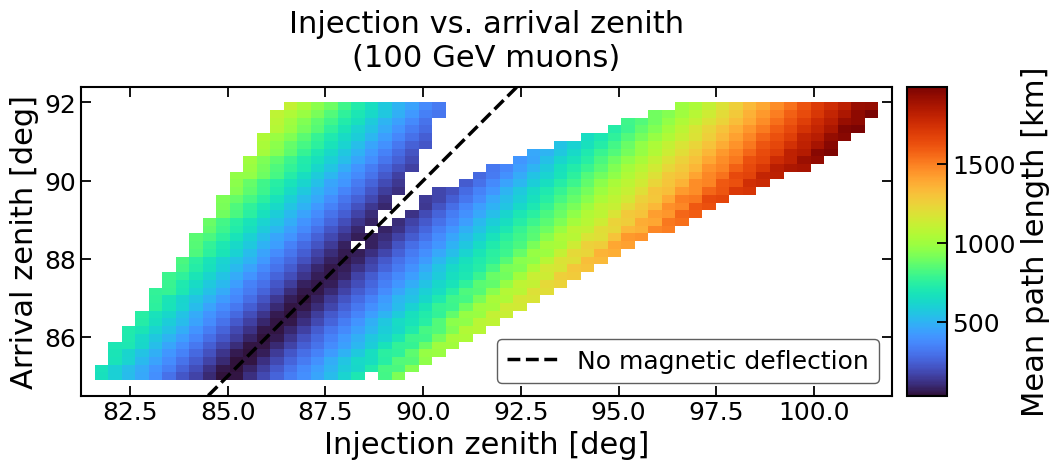

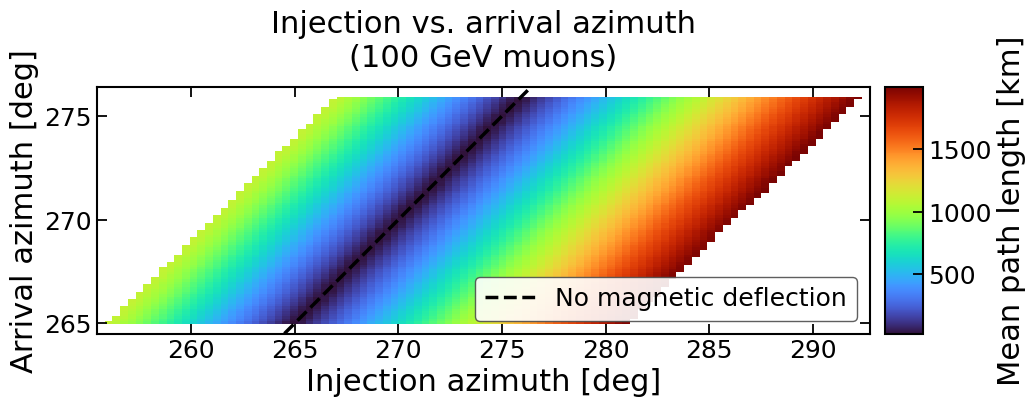

(<Figure size 1100x900 with 2 Axes>,
 <Axes: title={'center': 'Injection vs. arrival azimuth\n(100 GeV muons)'}, xlabel='Injection azimuth [deg]', ylabel='Arrival azimuth [deg]'>)

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ── Presentation style ────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "font.size": 20,
    "axes.titlesize": 22, "axes.labelsize": 22,
    "xtick.labelsize": 18, "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "axes.linewidth": 1.5,
    "xtick.major.size": 7, "ytick.major.size": 7,
    "xtick.major.width": 1.3, "ytick.major.width": 1.3,
    "xtick.minor.size": 4, "ytick.minor.size": 4,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})

# ── Options ───────────────────────────────────────────────────────────────
N_BINS_ZEN_INJ = 60
N_BINS_ZEN     = 40
N_BINS_AZ_INJ  = 100
N_BINS_AZ      = 100
CMAP           = "turbo"

# ── Load and clean data ───────────────────────────────────────────────────
zen            = np.asarray(res["detector_zenith_deg"]).ravel()
az             = np.asarray(res["detector_azimuth_deg"]).ravel()
zen_inj        = np.asarray(res["injection_zenith_deg"]).ravel()
az_inj         = np.asarray(res["injection_azimuth_deg"]).ravel()
path_length_km = np.asarray(res["path_length_m"]).ravel() / 1000.0
success        = np.asarray(res["success"], dtype=bool).ravel()

valid = (success
         & np.isfinite(zen_inj) & np.isfinite(zen)
         & np.isfinite(az_inj)  & np.isfinite(az)
         & np.isfinite(path_length_km))

zen_inj, zen   = zen_inj[valid], zen[valid]
az_inj, az     = az_inj[valid], az[valid]
path_length_km = path_length_km[valid]

if az.size == 0:
    raise ValueError("No successful crossings to plot.")

# ── Edges from each variable's own data range ────────────────────────────
def bin_edges(values, n_bins):
    lo, hi = values.min(), values.max()
    pad = max(0.5, 0.02 * (hi - lo))
    return np.linspace(lo - pad, hi + pad, n_bins + 1)

# ── Plot ──────────────────────────────────────────────────────────────────
def plot_2d_histogram(x, y, weights, x_edges, y_edges,
                      xlabel, ylabel, title, cmap=CMAP):
    H_sum, _, _   = np.histogram2d(x, y, bins=[x_edges, y_edges], weights=weights)
    H_count, _, _ = np.histogram2d(x, y, bins=[x_edges, y_edges])

    H_mean = np.divide(H_sum, H_count, out=np.zeros_like(H_sum), where=H_count > 0)
    H_mean = np.ma.masked_where(H_count == 0, H_mean)
    if H_mean.count() == 0:
        raise ValueError("No filled bins to plot.")

    cm_ = plt.get_cmap(cmap).copy()
    cm_.set_bad("white")

    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.pcolormesh(x_edges, y_edges, H_mean.T, cmap=cm_,
                       shading="flat", rasterized=True)

    # No-deflection line (y = x), drawn only where the ranges overlap
    d_lo = max(x_edges[0], y_edges[0])
    d_hi = min(x_edges[-1], y_edges[-1])
    if d_hi > d_lo:
        ax.plot([d_lo, d_hi], [d_lo, d_hi], color="black", ls="--", lw=2.5,
                label="No magnetic deflection")
        ax.legend(loc="best", frameon=True, facecolor="white",
                  edgecolor="0.3", framealpha=0.9)

    # Keep each axis at its own data range, with equal aspect (1° = 1°)
    ax.set_xlim(x_edges[0], x_edges[-1])
    ax.set_ylim(y_edges[0], y_edges[-1])
    ax.set_aspect("equal", adjustable="box")

    # Colorbar matched to the axes height
    cax = make_axes_locatable(ax).append_axes("right", size="5%", pad=0.15)
    cb = fig.colorbar(im, cax=cax)
    cb.set_label("Mean path length [km]")
    cb.ax.tick_params(labelsize=18)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, pad=15)

    fig.tight_layout()
    plt.show()
    return fig, ax

E_label = f"{E_TOT_GEV[0]:g} GeV muons"

plot_2d_histogram(
    zen_inj, zen, path_length_km,
    bin_edges(zen_inj, N_BINS_ZEN_INJ), bin_edges(zen, N_BINS_ZEN),
    xlabel="Injection zenith [deg]",
    ylabel="Arrival zenith [deg]",
    title=f"Injection vs. arrival zenith\n({E_label})",
)
plot_2d_histogram(
    az_inj, az, path_length_km,
    bin_edges(az_inj, N_BINS_AZ_INJ), bin_edges(az, N_BINS_AZ),
    xlabel="Injection azimuth [deg]",
    ylabel="Arrival azimuth [deg]",
    title=f"Injection vs. arrival azimuth\n({E_label})",
)